In [2]:
import kagglehub

# Download latest version
path = kagglehub.competition_download('titanic')

print("Path to competition files:", path)

Path to competition files: /kaggle/input/competitions/titanic


In [3]:
#Libraries
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

In [4]:
#Models 
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [5]:
#Evals
from sklearn.model_selection import cross_val_score
from sklearn.metrics import accuracy_score
import warnings
warnings.filterwarnings('ignore')

In [6]:
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10,6)

In [7]:
#Load dataset
train = pd.read_csv('/kaggle/input/competitions/titanic/train.csv')
test = pd.read_csv('/kaggle/input/competitions/titanic/test.csv')

print(f'Training data size: {train.shape}')
print(f'Testing data size: {test.shape}')

train.head()

Training data size: (891, 12)
Testing data size: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [8]:
test.head()

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [9]:
'''
Always make sure to find the number of missing entries in each feature/column
'''
print('Missing values in Training Dataset')
print(train.isnull().sum())
print('\nSurvival Rate:', train['Survived'].mean())

age_missing = train[train['Age'].isna()]
male_cnt = (age_missing['Sex'] == 'male').sum()
female_cnt = (age_missing['Sex'] == 'female').sum()
# print(age_missing)
print('\nMale Count in People with age missing', male_cnt)
print('\nFemale Count in People with age missing', female_cnt)

Missing values in Training Dataset
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

Survival Rate: 0.3838383838383838

Male Count in People with age missing 124

Female Count in People with age missing 53


In [10]:
#People with a cabin number who survived titanic 
cnt_people_with_cabin = (train['Cabin'].notnull()).sum()
cnt_people_with_cabin_and_survived = ((train['Cabin'].notnull()) & (train['Survived'] == 1)).sum()
print(cnt_people_with_cabin, cnt_people_with_cabin_and_survived)
print(cnt_people_with_cabin_and_survived / cnt_people_with_cabin * 100)

204 136
66.66666666666666


In [11]:
#Find number of upper class(1), middle class(2) and lower class(3) people who survived the Titanic
class_total_count = train['Pclass'].value_counts()
class_survived_count = train[train['Survived'] == 1]['Pclass'].value_counts()
print(class_total_count,class_survived_count)

class_percentages = train["Pclass"].value_counts(normalize=True) * 100
print(class_percentages)

survivor_in_each_class = train.groupby('Pclass')['Survived'].mean()
print('\nSurvival Rate in each class:', survivor_in_each_class * 100)

Pclass
3    491
1    216
2    184
Name: count, dtype: int64 Pclass
1    136
3    119
2     87
Name: count, dtype: int64
Pclass
3    55.106622
1    24.242424
2    20.650954
Name: proportion, dtype: float64

Survival Rate in each class: Pclass
1    62.962963
2    47.282609
3    24.236253
Name: Survived, dtype: float64


      Age  Count
0   24.00     30
1   22.00     27
2   18.00     26
3   28.00     25
4   30.00     25
..    ...    ...
83  24.50      1
84   0.67      1
85   0.42      1
86  34.50      1
87  74.00      1

[88 rows x 2 columns]


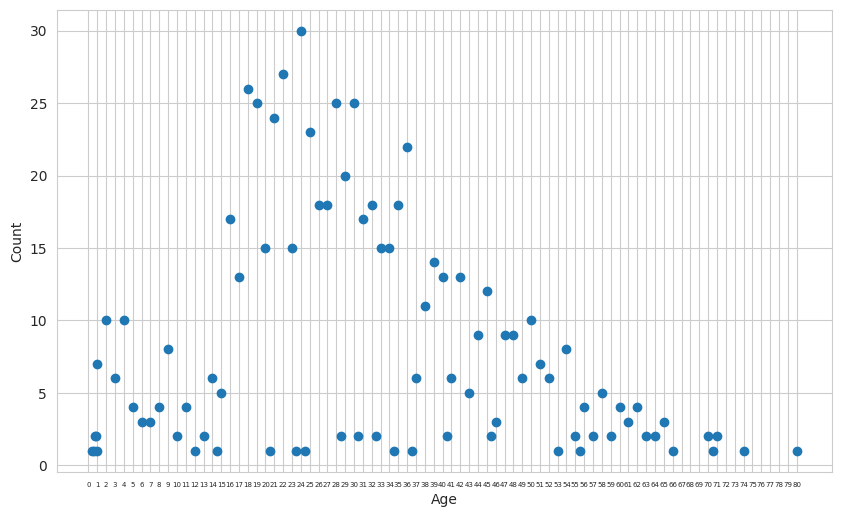

In [12]:
#Age distribution
age_counts = train['Age'].value_counts().reset_index(name='Count')
print(age_counts)
plt.scatter(age_counts['Age'],age_counts['Count'])
plt.xlabel('Age')
plt.xticks(range(0,81,1),fontsize=5)
plt.ylabel('Count')
plt.show()

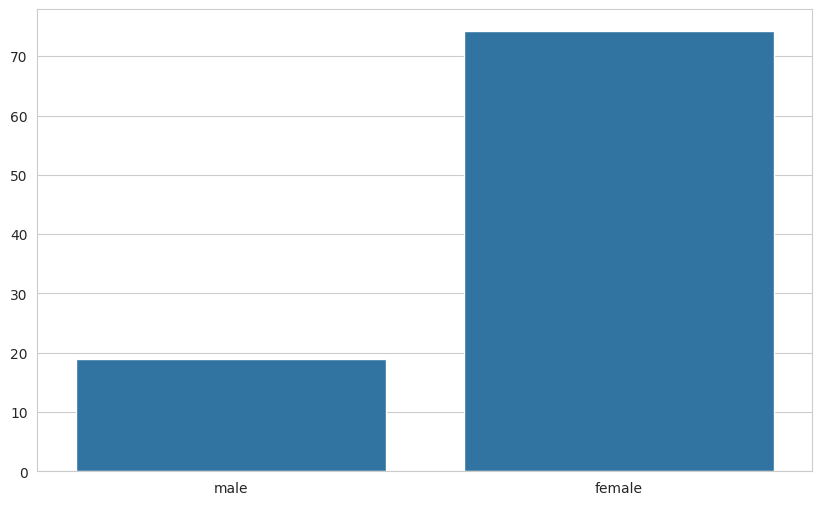

In [13]:
# survival_by_gender = train.groupby('Sex')['Survived'].mean()
sns.barplot(data=train, x="Sex", y="Survived", estimator=lambda x: x.mean() * 100,errorbar=None)
plt.title("")
plt.xlabel("")
plt.ylabel("")

plt.show()

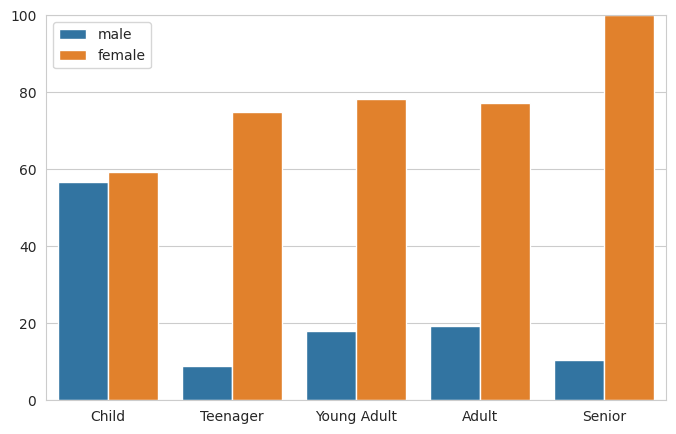

Pclass           1      2      3
AgeGroup                        
Child         7.50  42.50  50.00
Teenager     36.67  20.00  43.33
Young Adult  36.50  29.93  33.58
Adult        70.51  23.08   6.41
Senior       60.00  20.00  20.00


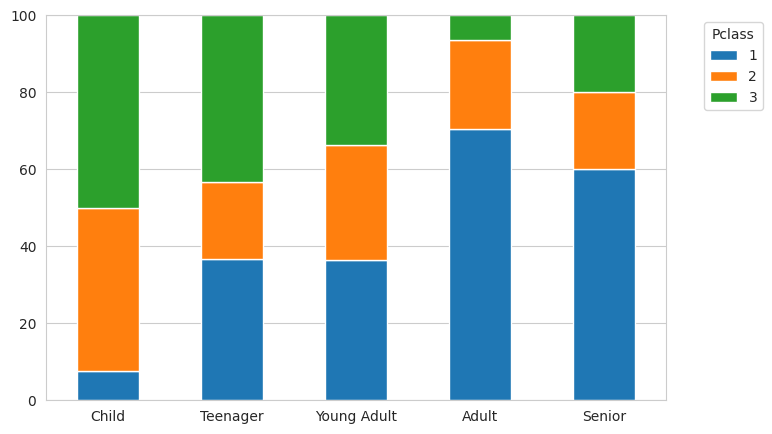

In [14]:
bins = [0, 12, 18, 35, 60, 100]
labels = ["Child", "Teenager", "Young Adult", "Adult", "Senior"]

train_temp = train.copy()
train_temp["AgeGroup"] = pd.cut(train_temp["Age"], bins=bins, labels=labels)

# Plot survival rates out of 100 grouped by age group and sex
plt.figure(figsize=(8, 5))
sns.barplot(
    data=train_temp,
    x="AgeGroup",
    y="Survived",
    hue="Sex",
    estimator=lambda x: x.mean() * 100,
    errorbar=None,
)

plt.ylim(0, 100)
plt.title("")
plt.xlabel("")
plt.ylabel("")
plt.legend(title="")

plt.show()

survivors = train_temp[train_temp["Survived"] == 1]

# Calculate the percentage distribution of Pclass within each AgeGroup
class_by_age = (
    pd.crosstab(survivors["AgeGroup"], survivors["Pclass"], normalize="index")
    * 100
).round(2)

print(class_by_age)
class_by_age.plot(
    kind="bar", stacked=True, figsize=(8, 5)
)

plt.ylim(0, 100)
plt.title("")
plt.xlabel("")
plt.ylabel("")
plt.xticks(rotation=0)
plt.legend(title="Pclass", bbox_to_anchor=(1.05, 1), loc="upper left")

plt.show()

In [15]:
def extract_title(name):
    """Extract title from passenger name"""
    title = name.split(',')[1].split('.')[0].strip()
    # Group rare titles
    if title in ['Lady', 'Countess','Capt', 'Col', 'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona']:
        return 'Rare'
    elif title in ['Mlle', 'Ms']:
        return 'Miss'
    elif title == 'Mme':
        return 'Mrs'
    return title

In [16]:
def engineer_features(df):
  df = df.copy()
  df['Title'] = df['Name'].apply(extract_title)
  df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
  df['IsAlone'] = (df['FamilySize'] == 1).astype(int)
  df['Age'] = df['Age'].fillna(df['Age'].median())
  df['Fare'] = df['Fare'].fillna(df['Fare'].median())
  df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
  return df

# Apply feature engineering
train_fe = engineer_features(train)
test_fe = engineer_features(test)

print("New features created!")
print(train_fe[['Name', 'Title', 'FamilySize', 'IsAlone']].head())

New features created!
                                                Name Title  FamilySize  \
0                            Braund, Mr. Owen Harris    Mr           2   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...   Mrs           2   
2                             Heikkinen, Miss. Laina  Miss           1   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)   Mrs           2   
4                           Allen, Mr. William Henry    Mr           1   

   IsAlone  
0        0  
1        0  
2        1  
3        0  
4        1  


In [17]:
feature_columns = ['Pclass', 'Sex', 'Age', 'Fare', 'Embarked', 'FamilySize', 'IsAlone', 'Title']

# Combine train and test for consistent encoding
combined = pd.concat([train_fe[feature_columns], test_fe[feature_columns]], axis=0)

# Convert categorical variables to numeric (one-hot encoding)
combined_encoded = pd.get_dummies(combined, columns=['Sex', 'Embarked', 'Title'], drop_first=True)

In [18]:
X_train = combined_encoded[:len(train_fe)]
X_test = combined_encoded[len(train_fe):]
y_train = train_fe['Survived']

print(f"Training features shape: {X_train.shape}")
print(f"Test features shape: {X_test.shape}")
print(f"\nFeatures used: {list(X_train.columns)}")

Training features shape: (891, 13)
Test features shape: (418, 13)

Features used: ['Pclass', 'Age', 'Fare', 'FamilySize', 'IsAlone', 'Sex_male', 'Embarked_Q', 'Embarked_S', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare', 'Title_the Countess']


In [19]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)

# Cross-validation to evaluate model
lr_cv_scores = cross_val_score(lr_model, X_train, y_train, cv=5, scoring='accuracy')
print("Logistic Regression Cross-Validation Scores:")
print(f"  Individual folds: {lr_cv_scores}")
print(f"  Mean CV Accuracy: {lr_cv_scores.mean():.4f} (+/- {lr_cv_scores.std():.4f})")

# Train on full training set
lr_model.fit(X_train, y_train)
print("\nLogistic Regression trained!")

Logistic Regression Cross-Validation Scores:
  Individual folds: [0.81564246 0.82022472 0.80898876 0.79775281 0.84831461]
  Mean CV Accuracy: 0.8182 (+/- 0.0169)

Logistic Regression trained!


In [20]:
lr_predictions = lr_model.predict(X_test)

print(f"Predictions made: {len(lr_predictions)}")
print(f"Predicted survival rate: {lr_predictions.mean():.2%}")

Predictions made: 418
Predicted survival rate: 39.23%


In [21]:
lr_submission = pd.DataFrame({
    'PassengerId': test_fe['PassengerId'],
    'Survived': lr_predictions
})
lr_submission.to_csv('submission_logistic_regression.csv', index=False)
